## Import

In [49]:
import os, shutil, random, glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

## Settings

In [50]:
IMAGES_PER_CLASS = 3000        # we use a small subset to train faster
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 5
CLASSES = ["Parasitized", "Uninfected"]

# Folder structure required by the assignment
PROJECT_DIR = "/content/malaria_project"
TRAIN_DIR = PROJECT_DIR + "/data/train"
TEST_DIR = PROJECT_DIR + "/data/test"
MODELS_DIR = PROJECT_DIR + "/models"
os.makedirs(MODELS_DIR, exist_ok=True)
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Data

In [51]:
from google.colab import drive
drive.mount("/content/drive")

#show the zip files in my drive, so I can find the exact name
!ls /content/drive/MyDrive | grep -i zip

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Malaria.zip


In [52]:
# Put the exact name of your ZIP file here (see the list above)
ZIP_PATH = "/content/drive/MyDrive/Malaria.zip"

#!unzip -q "$ZIP_PATH" -d /content/raw_data

# Find the two class folders
src = {}
for root, dirs, files in os.walk("/content/raw_data"):
    name = os.path.basename(root)
    if name in CLASSES and any(f.lower().endswith(".png") for f in files):
        src[name] = root
print(src)
assert set(src) == set(CLASSES), "Parasitized / Uninfected folders not found"

{'Parasitized': '/content/raw_data/cell_images/cell_images/Parasitized', 'Uninfected': '/content/raw_data/cell_images/cell_images/Uninfected'}


## Train / Test split

In [53]:
for c in CLASSES:
    files = [f for f in os.listdir(src[c]) if f.lower().endswith(".png")]
    random.shuffle(files)
    files = files[:IMAGES_PER_CLASS]
    n_test = int(len(files) * 0.2)

    # create the destination folders right before copying
    os.makedirs(f"{TEST_DIR}/{c}", exist_ok=True)
    os.makedirs(f"{TRAIN_DIR}/{c}", exist_ok=True)

    for i, f in enumerate(files):
        dest = TEST_DIR if i < n_test else TRAIN_DIR
        shutil.copy(os.path.join(src[c], f), f"{dest}/{c}/{f}")

for folder in [TRAIN_DIR, TEST_DIR]:
    for c in CLASSES:
        print(folder.split("/")[-1], c, len(os.listdir(f"{folder}/{c}")))

train Parasitized 4380
train Uninfected 4386
test Parasitized 1180
test Uninfected 1175


## Data Visualizations

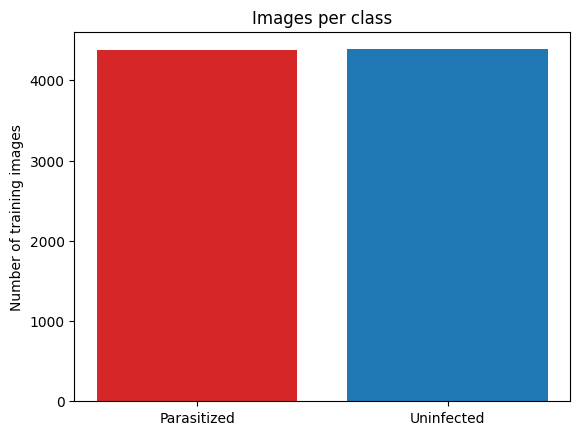

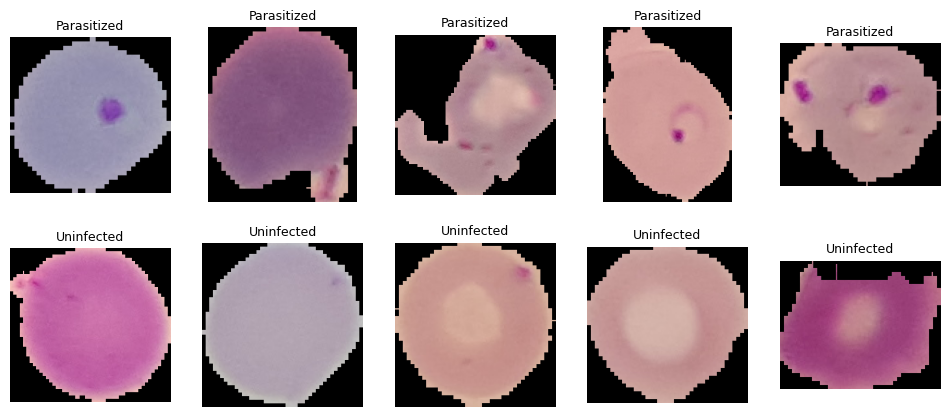

In [54]:
# Visualization 1: number of images per class
counts = [len(os.listdir(f"{TRAIN_DIR}/{c}")) for c in CLASSES]
plt.bar(CLASSES, counts, color=["tab:red", "tab:blue"])
plt.ylabel("Number of training images")
plt.title("Images per class")
plt.show()

# Some example images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for r, c in enumerate(CLASSES):
    for k, f in enumerate(random.sample(os.listdir(f"{TRAIN_DIR}/{c}"), 5)):
        axes[r, k].imshow(Image.open(f"{TRAIN_DIR}/{c}/{f}"))
        axes[r, k].set_title(c, fontsize=9)
        axes[r, k].axis("off")
plt.show()

## Interpretation
The 2 classes have the same number of images, so the dataset is balanced. This means accuracy is a faire metric and the model is not pushed to favor one class

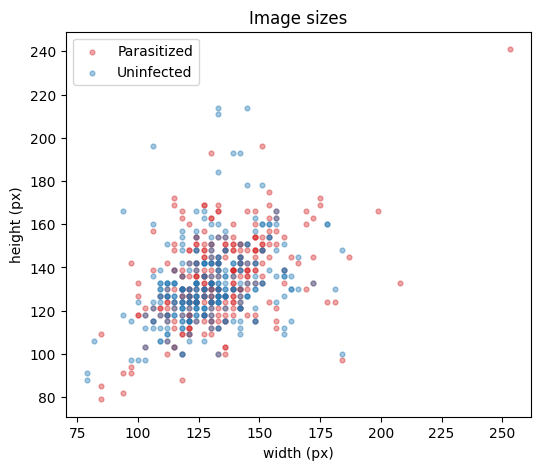

In [55]:
# visualization 2: image sizes
plt.figure(figsize=(6, 5))
for c, color in zip(CLASSES, ["tab:red", "tab:blue"]):
    sizes = [Image.open(f"{TRAIN_DIR}/{c}/{f}").size
             for f in random.sample (os.listdir(f"{TRAIN_DIR}/{c}"), 300)]
    w, h = zip(*sizes)
    plt.scatter(w, h, alpha=0.4, s=12, label=c, color=color)
plt.xlabel("width (px)"); plt.ylabel("height (px)")
plt.title("Image sizes")
plt.legend()
plt.show()

## Interpretation
The image do not all have the same size, so we must resize them all to 128*128 before training the model

Parasitized average: 104.0
Uninfected average: 112.8


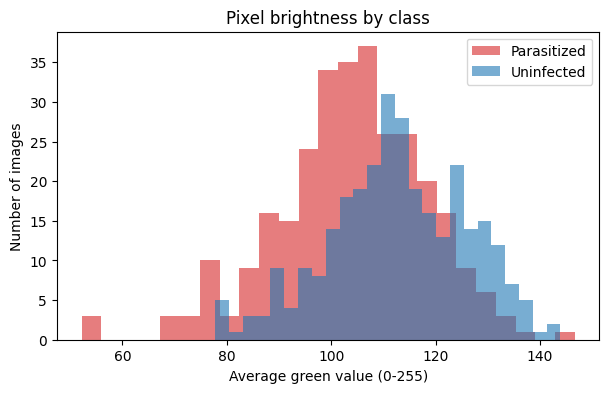

In [56]:
# Visualization 3: average brightness of the green channel
plt.figure(figsize=(7, 4))
for c, color in zip(CLASSES, ["tab:red", "tab:blue"]):
    values = []
    for f in random.sample(os.listdir(f"{TRAIN_DIR}/{c}"), 300):
        img = np.array(Image.open(f"{TRAIN_DIR}/{c}/{f}").convert("RGB").resize(IMG_SIZE))
        values.append(img[:, :, 1].mean())
    plt.hist(values, bins=25, alpha=0.6, label=c, color=color)
    print(c, "average:", round(np.mean(values), 1))
plt.xlabel("Average green value (0-255)"); plt.ylabel("Number of images")
plt.title("Pixel brightness by class"); plt.legend(); plt.show()

## Interpretation
The infected cells contain a dark stained parasite that means their pixel values differ a little from  healthy cells. The 2 curves overlap, so a simple average is not enough. we need a CNN that can recognize shapes

# Preprocessing

In [57]:
common = dict(image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='binary', class_names=CLASSES)

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED, **common)
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED, **common)
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, shuffle=False, **common)

Found 8766 files belonging to 2 classes.
Using 7013 files for training.
Found 8766 files belonging to 2 classes.
Using 1753 files for validation.
Found 2355 files belonging to 2 classes.


# Model Creation

In [58]:
#I used MobileNetV2, a model already trained on millions of images and add one output layer for our 2 classes
base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = layers.RandomFlip("horizontal_and_vertical")(inputs)
x = layers.Rescaling(1/127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 66s 188ms/step - accuracy: 0.8173 - loss: 0.3853 - val_accuracy: 0.8842 - val_loss: 0.2794
Epoch 2/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.8886 - loss: 0.2736 - val_accuracy: 0.8939 - val_loss: 0.2429
Epoch 3/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.9008 - loss: 0.2439 - val_accuracy: 0.9064 - val_loss: 0.2262
Epoch 4/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.9069 - loss: 0.2358 - val_accuracy: 0.9116 - val_loss: 0.2178
Epoch 5/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.9109 - loss: 0.2287 - val_accuracy: 0.9150 - val_loss: 0.2132


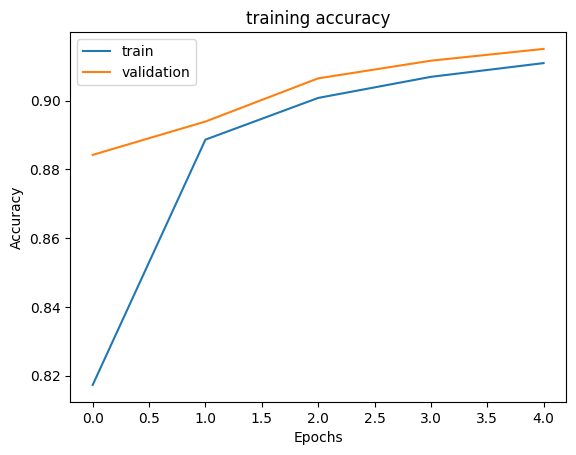

In [59]:
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("Epochs"); plt.ylabel("Accuracy"); plt.legend();
plt.title("training accuracy"); plt.show()

# Model Testing

74/74 ━━━━━━━━━━━━━━━━━━━━ 21s 241ms/step
Accuracy : 0.9291
Precision: 0.9242
Recall   : 0.9345
F1-score : 0.9293
ROC AUC  : 0.9783

              precision    recall  f1-score   support

 Parasitized       0.93      0.92      0.93      1180
  Uninfected       0.92      0.93      0.93      1175

    accuracy                           0.93      2355
   macro avg       0.93      0.93      0.93      2355
weighted avg       0.93      0.93      0.93      2355



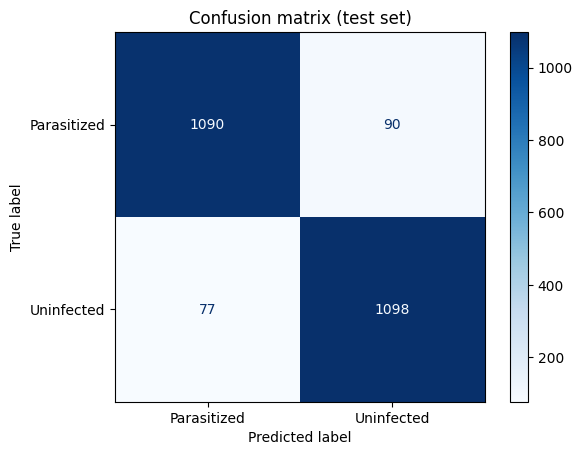

In [60]:
y_true = np.concatenate([y.numpy() for _, y in test_ds]).ravel().astype(int)
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred), 4))
print("Recall   :", round(recall_score(y_true, y_pred), 4))
print("F1-score :", round(f1_score(y_true, y_pred), 4))
print("ROC AUC  :", round(roc_auc_score(y_true, y_prob), 4))
print()
print(classification_report(y_true, y_pred, target_names=CLASSES))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASSES).plot(cmap="Blues")
plt.title("Confusion matrix (test set)"); plt.show()

# Prediction Function

In [61]:
def predict_image(path):
    img = keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = np.expand_dims(keras.utils.img_to_array(img), 0)
    p = float(model.predict(arr, verbose=0)[0][0])   # probability of "Uninfected"
    label = CLASSES[int(p >= 0.5)]
    confidence = p if p >= 0.5 else 1 - p
    return label, round(confidence, 4)

example = glob.glob(TEST_DIR + "/Parasitized/*.png")[0]
print(predict_image(example))

('Parasitized', 0.8805)


# Save Model

In [62]:
model.save(MODELS_DIR + "/malaria_model.h5")
print("Model saved")

# Copy the model to your Google Drive so you do not lose it
os.makedirs("/content/drive/MyDrive/malaria_project", exist_ok=True)
shutil.copy(MODELS_DIR + "/malaria_model.h5", "/content/drive/MyDrive/malaria_project/malaria_model.h5")

Model saved


'/content/drive/MyDrive/malaria_project/malaria_model.h5'

In [63]:
import shutil, os, random

def copy_sample(src_dir, dst_dir, n):
    for c in CLASSES:
        os.makedirs(f"{dst_dir}/{c}", exist_ok=True)
        files = os.listdir(f"{src_dir}/{c}")
        random.shuffle(files)
        for f in files[:n]:
            shutil.copy(f"{src_dir}/{c}/{f}", f"{dst_dir}/{c}/{f}")

copy_sample(TRAIN_DIR, "/content/repo_data/train", 500)
copy_sample(TEST_DIR, "/content/repo_data/test", 100)

shutil.make_archive("/content/drive/MyDrive/malaria_project/data_sample", "zip", "/content/repo_data")
print("Saved to Drive")

Saved to Drive
